# Exercices 6

[Télécharger l'exercice](../06_exercice.zip)

# Exercise : Contamination dans une rivière

Le but de cet exercice est d'implémenter une équation d'advection-diffusion-réaction en 1D dans un cas réaliste.

La digue du bassin de résidus d'une mine d'or s'écroule et relâche de l'eau contaminée au cyanure dans une rivière. (Ce scénario est inspiré par la [catastrophe de 2000 de Baia Mare en Roumanie](https://en.wikipedia.org/wiki/2000_Baia_Mare_cyanide_spill). L'eau toxique va alors être transportée dans la rivière (par advection) à la même vitesse que son débit. Durant ce transport, le polluant va aussi se diffuser et se dégrader dans le cours d'eau. L'évolution de la contamination peut être décrite avec une équation de diffusion-advection-réaction :

$$\frac{\partial C}{\partial t} = - \frac{\partial Q}{\partial x} - v \frac{\partial C}{\partial x}\ - \gamma C,$$

avec 

$$Q = - D\frac{\partial C}{\partial x}.$$

1) Comme condition initiale, distribuez l'eau polluée entre les distances de 400 et 600 m et supposez que cette eau n'est pas diluée dans la rivière (`Cinit = 1000`). Utilisez une condition limite en aval de flux nul, et une condition limite fixe en amont pour forcer l'arrivée d'eau non contaminée. Implémentez le modèle dans un bloc de code ci-dessous en vous référant au tableau ci-dessous pour les paramètres. Profitez-en pour essayer les deux types de discrétisation ("upwind" et "downwind") pour l'advection, qui diffèrent par un simple décalage des indices. Quelle méthode fonctionne et quelle méthode ne fonctionne pas ?

2) Dans un deuxième temps, nous allons implémenter le même modèle en inversant l'axe $x$ de façon symétrique : i) la fuite est localisée sur le côté droit, ii) le signe de la vitesse est inversé, iii) les conditions aux bords sont inversées. Nous utiliserons le même code qui fonctionnera avec le paramètre `Q=1` dans le cas original et `Q=2` dans le cas inversé. Il s'agira donc d'introduire le paramètre `Q` ainsi que des clauses conditionnelles dans le code spécifiques à chaque cas (`Q=1` pour l'original et `Q=2` pour l'inverse).

### Paramètres pour le problème de la rivière

| **Paramètres**                             | **Valeurs**      |
|--------------------------------------------|------------------|
| Longueur du domaine modélisé               | 10 km            |
| Concentration initiale du cyanure          | 1000 ppm         |
| Coordonnées de la fuite (Q=1)              | 400 à 600 m      |
| Coordonnées de la fuite (Q=2)              | 9400 à 9600 m    |
| Diffusivité du cyanure                     | 5 m²/s           |
| Constante de décroissance $\gamma$         | 0.0001           |
| Vitesse de la rivière (Q=1)                | 2 m/s            |
| Vitesse de la rivière (Q=2)                | -2 m/s           |
| Nombre de cellules                         | 500              |
| Temps total                                | 1.5 hrs          |
 
 
![](./fig/cyanide.png)
*Représentation de l'advection et diffusion d'une fuite de cyanure dans une rivière*
 
### ✅ **À vous de faire !** 

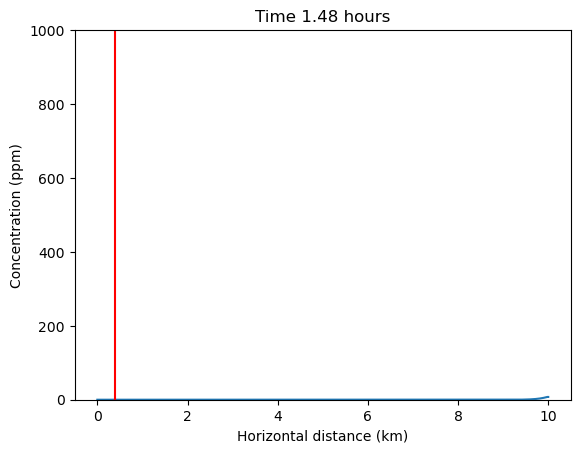

In [1]:
# Correction par Thomas Gregov (Octobre 2025)

# import librairies
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

# version du code à effectuer
Q = 1

# physical parameters
D = 5                   # diffusivité en m2/s
Lx = 10000              # longeur du domaine modélisé en m
C_norm = 0              # concentration normale de cyanure en ppm
C_ini = 1000            # concentration initiale en ppm
gamma = 0.0001          # constante de décroissance
ttot = 1.5              # temps total en heures
h2s = 3600
C_side = 0              # concentration au bord fixe
if Q == 1:
    V = 2                  # vitesse rivière pour Q=1
    xg_fuite = 400         # limite gauche de la fuite Q=1
    xd_fuite = 600         # limite droite de la fuite Q=1
if Q == 2:
    V = -2
    xg_fuite = 9400        
    xd_fuite = 9600


# numerical parameters
nx = 500                      # nombre de cellules
dx = Lx / (nx - 1)            # taille d'une cellule
x = np.linspace(0, Lx, nx)    # coordonees des point du maillage
dt1 = dx**2 / (2.1 * D)        
dt2 = 0.1*(dx/abs(V))
dt = min(dt1, dt2)            # condition sur le pas de temps
nt = int((ttot*h2s)/dt)       # nombre de pas de temps
nout = 100                    # afficher la figure chaque 100e step
time = 0                      # initialisation du temps

# inital conditions
C = np.ones(nx) * C_norm
C[int(xg_fuite/dx):int(xd_fuite/dx)] = C_ini
# create the figure outside the loop 
fig, ax = plt.subplots()

# loop
for it in range(nt):
    time += dt #track time
    # Mettre a jour le flux q en fonction de C 
    q = - D * ( C[1:] - C[:-1] ) / dx
    # Mettre a jour dCdt
    dCdt = - ( q[1:] - q[:-1] ) / dx
    # Mettre a jour C
    C[1:-1] += dCdt * dt
    # mettre à jour la vitesse d'advection
    dCdt_a = - V * ( C[1:] - C[:-1] ) / dx
    # CORRECTEUR: pour être encore plus général, tu peux définir ce critère
    # en fonction du signe de la vitesse V directement, plutôt qu'en fonction
    # de la question; ainsi il y aura toujours deux cas à prendre en compte 
    # (if v > 0: ...; else: ...), même s'il y a plusieurs sous-questions
    # mettre a jour C en fonction de l'advection
    if Q == 1:
        C[1:] += dt*dCdt_a # condition upwind pour la version Q=1
    elif Q == 2:
        C[:-1] += dt*dCdt_a # condition downwind pour la version Q=2
    # mettre à jour la reaction et C pour la réaction
    dCdt_r = - gamma * C
    C += dt*dCdt_r

    # mise à jour des conditions aux marges
    if Q == 1: 
        C[0] = C_side        # amont: limite fixe pour forcer de l'eau propre
        C[-1] = C[-2]   # aval: flux nul pour evacuer
    
    if Q == 2:
        C[0] = C[1]     # aval: flux nul pour évacuer
        C[-1] = C_side       # amont: limite fixe pour forcer de l'eau propre
    
    # plot
    if it % nout == 0:
        clear_output(wait=True) 
        ax.cla() 
        # CORRECTEUR: il est ici préférable d'afficher l'axe des x en km 
        # plutôt qu'en m pour rendre le graphique plus lisible; on va
        # donc diviser les x par 1000
        #ax.plot(x, C)
        ax.plot(x/1000, C)
        ax.set_title("Time " + str(round(time/h2s, 2)) + " hours")
        ax.set_ylim(0,1000)
        #ax.plot([xg_fuite, xg_fuite], [0,1000], 'r')
        #ax.plot([xd_fuite, xd_fuite], [0,1000], 'r')
        ax.plot([xg_fuite/1000, xg_fuite/1000], [0,1000], 'r')
        #ax.set_xlabel('Horizontal distance (m)')
        ax.set_xlabel('Horizontal distance (km)')
        ax.set_ylabel('Concentration (ppm)')
        display(fig)
        plt.pause(0.1)